In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
os.environ['JAX_PLATFORM_NAME'] = 'cpu'  # Avoid Metal issues on M1
os.environ['AUTO_DIR'] = '/Users/juannat/Documents/research/auto-07p'  # Required for bifurcation_finder (see docs/INSTALL_AUTO.md)


In [3]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from pprint import pprint

from tipbox.bifurcation.polynomial_model import generate_random_polynomial_model, simulate_to_equilibrium
from tipbox.bifurcation.bifurcation_finder import find_all_bifurcations


# High-Level API

### 1. Bifurcation-induced

In [4]:
import jax
from tipbox import generate

time, traj, info = generate.generate(
    key=jax.random.PRNGKey(123),
    steps_before_transition=1,
    num_timesteps=500,
    sigma_tilde=0.01,
    tipping_type='fold',
    null_simulation=False,
)


W0000 00:00:1762827479.409052 21990839 mps_client.cc:510] WARNING: JAX Apple GPU support is experimental and not all JAX functionality is correctly supported!
I0000 00:00:1762827479.435624 21990839 service.cc:145] XLA service 0x1377d2bd0 initialized for platform METAL (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1762827479.435638 21990839 service.cc:153]   StreamExecutor device (0): Metal, <undefined>
I0000 00:00:1762827479.436810 21990839 mps_client.cc:406] Using Simple allocator.
I0000 00:00:1762827479.436817 21990839 mps_client.cc:384] XLA backend will use up to 5726240768 bytes on device 0 for SimpleAllocator.


Metal device set to: Apple M1

systemMemory: 8.00 GB
maxCacheSize: 2.67 GB

Runner configured
Runner configured
gfortran -g -fopenmp -O -c model.f90 -o model.o
gfortran -g -fopenmp -O model.o -o model.exe /Users/juannat/Documents/research/auto-07p/lib/*.o
Starting model ...

  BR    PT  TY  LAB       a2         L2-NORM          x             y       
   1    47  UZ    2   5.00000E+00   2.71338E+00   2.30430E+00   1.43269E+00

 Total Time    0.256E-02
model ... done
Saving to b.outa2, s.outa2, and d.outa2 ... done
Deleting fort.* *.o *.exe *.*~ ... done
Runner configured
Runner configured
gfortran -g -fopenmp -O -c model.f90 -o model.o
gfortran -g -fopenmp -O model.o -o model.exe /Users/juannat/Documents/research/auto-07p/lib/*.o
Starting model ...

  BR    PT  TY  LAB       a3         L2-NORM          x             y       
   1    58  UZ    2   5.00000E+00   2.56994E+00   2.16373E+00   1.38667E+00

 Total Time    0.459E-02
model ... done
Saving to b.outa3, s.outa3, and d.outa3 ... don

In [5]:
pprint(info)

{'attempt': 1,
 'bifurcation': BifurcationPoint(bif_type='fold',
                                 bif_param_name='b10',
                                 bif_param_index=19,
                                 bif_value=1.101675787),
 'model': PolynomialModel(pars_a=Array([ 0.        ,  1.1563966 ,  0.27880964,  0.        ,  1.6256176 ,
        0.        , -1.4129233 , -0.        , -0.        , -0.        ],      dtype=float32),
                          pars_b=Array([ 0.        ,  0.5386325 ,  0.        ,  1.9474885 ,  0.        ,
       -0.897472  , -0.        , -0.21007437, -1.4727187 , -0.39989832],      dtype=float32),
                          s0=Array([0.3222313, 2.4456532], dtype=float32),
                          equi=Array([1.5127463, 1.14753  ], dtype=float32),
                          recovery_rate=4.3425092697143555),
 'param_value_transition': 1.1006847620010376,
 'sigma': 0.03140518441796303,
 'steps_before_transition': 1,
 'tipping_type': 'fold',
 'transition_index': 1499

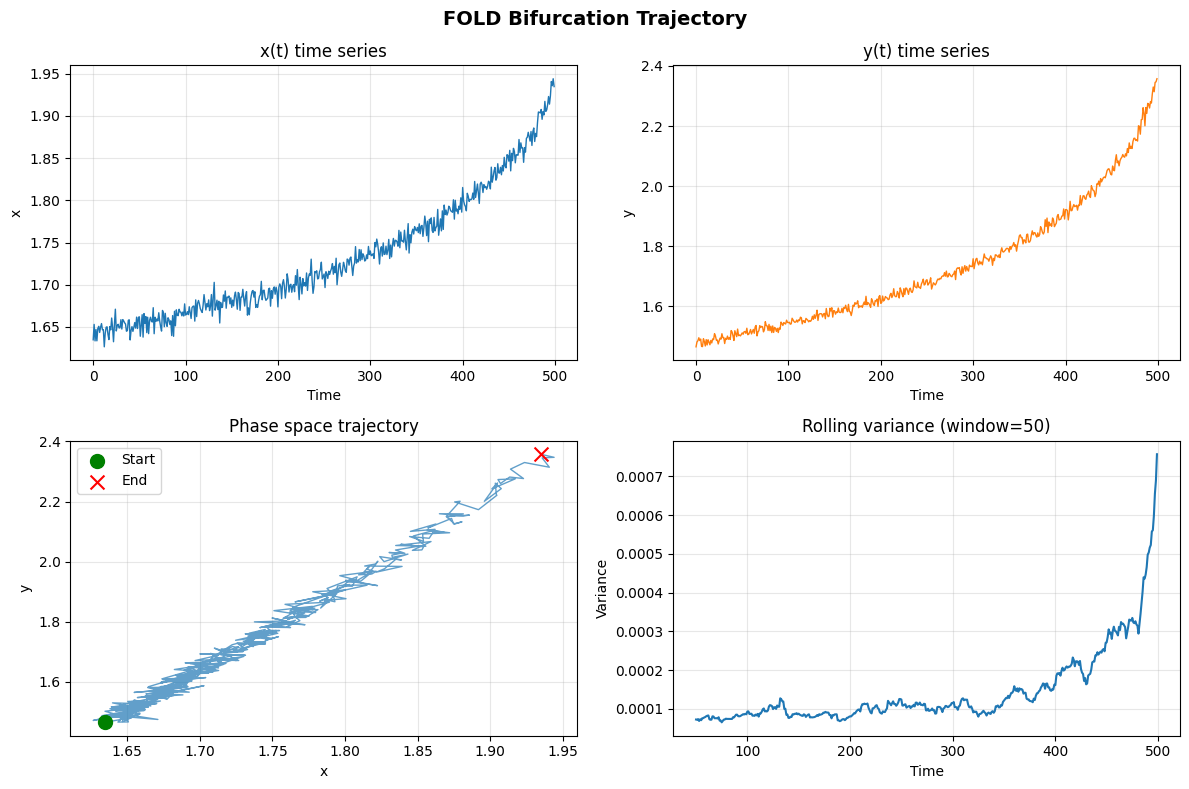

In [6]:
# Visualize the trajectory
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    
# Time series of x
axes[0, 0].plot(time, traj[:, 0], linewidth=1)
axes[0, 0].set_xlabel('Time')
axes[0, 0].set_ylabel('x')
axes[0, 0].set_title('x(t) time series')
axes[0, 0].grid(True, alpha=0.3)

# Time series of y
axes[0, 1].plot(time, traj[:, 1], linewidth=1, color='C1')
axes[0, 1].set_xlabel('Time')
axes[0, 1].set_ylabel('y')
axes[0, 1].set_title('y(t) time series')
axes[0, 1].grid(True, alpha=0.3)

# Phase space
axes[1, 0].plot(traj[:, 0], traj[:, 1], linewidth=1, alpha=0.7)
axes[1, 0].scatter(traj[0, 0], traj[0, 1], s=100, c='green', 
                    marker='o', label='Start', zorder=5)
axes[1, 0].scatter(traj[-1, 0], traj[-1, 1], s=100, c='red', 
                    marker='x', label='End', zorder=5)
axes[1, 0].set_xlabel('x')
axes[1, 0].set_ylabel('y')
axes[1, 0].set_title('Phase space trajectory')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Variance over time (early warning signal)
window = 50
rolling_var = [jnp.var(traj[max(0, i-window):i, 0]) 
                for i in range(window, len(traj))]
axes[1, 1].plot(time[window:], rolling_var, linewidth=1.5)
axes[1, 1].set_xlabel('Time')
axes[1, 1].set_ylabel('Variance')
axes[1, 1].set_title(f'Rolling variance (window={window})')
axes[1, 1].grid(True, alpha=0.3)

plt.suptitle(f'{info["tipping_type"].upper()} Bifurcation Trajectory', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


### 2. Rate-induced

In [7]:
import jax
from tipbox import generate

time, traj, info = generate.generate(
    key=jax.random.PRNGKey(123),
    steps_before_transition=1,
    num_timesteps=500,
    sigma_tilde=0.01,
    tipping_type='rate',
    null_simulation=False,
)


In [8]:
pprint(info)

{'attempt': 4,
 'param_value_transition': 2.97554612159729,
 'rate_system': 'saddle_node',
 'sigma': 0.01414213515818119,
 'steps_before_transition': 1,
 'system_config': {'dt': 0.01,
                   'epsilon': 1.25,
                   'initial_state_max': -1.0,
                   'initial_state_min': -10.0,
                   'lambda_max': 3.0,
                   't_end': 8.0,
                   't_start': -15.0,
                   'tip_threshold': 0.0},
 'tipping_type': 'rate',
 'transition_index': 1628}


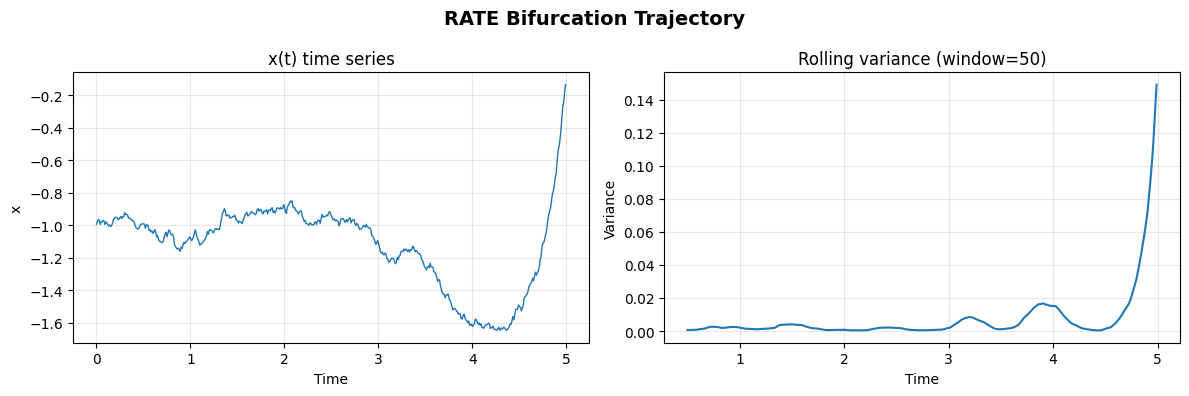

In [9]:
# Visualize the trajectory
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
# Time series of x
axes[0].plot(time, traj[:, 0], linewidth=1)
axes[0].set_xlabel('Time')
axes[0].set_ylabel('x')
axes[0].set_title('x(t) time series')
axes[0].grid(True, alpha=0.3)

# Variance over time (early warning signal)
window = 50
rolling_var = [jnp.var(traj[max(0, i-window):i, 0]) 
                for i in range(window, len(traj))]
axes[1].plot(time[window:], rolling_var, linewidth=1.5)
axes[1].set_xlabel('Time')
axes[1].set_ylabel('Variance')
axes[1].set_title(f'Rolling variance (window={window})')
axes[1].grid(True, alpha=0.3)

plt.suptitle(f'{info["tipping_type"].upper()} Bifurcation Trajectory', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
